<a href="https://colab.research.google.com/github/ireniusliqfenermaward-maker/DATA_SCIENCE/blob/main/TUGAS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STUDI KASUS 1: KLASIFIKASI DIAGNOSIS MEDIS (DIABETES)

--- 1. Tampilan 5 Baris Pertama Data Diabetes ---
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

--- 2. Identifikasi Missing Value (Nilai 0) ---
Jumlah nilai 0 pada kolom Glucose: 5
Jumlah nilai 0 pada kolom BloodPressure: 35
Jumlah nilai 0 pada kolom SkinThickness: 227
Jumlah nilai 0 pada kol

<Figure size 1000x500 with 0 Axes>

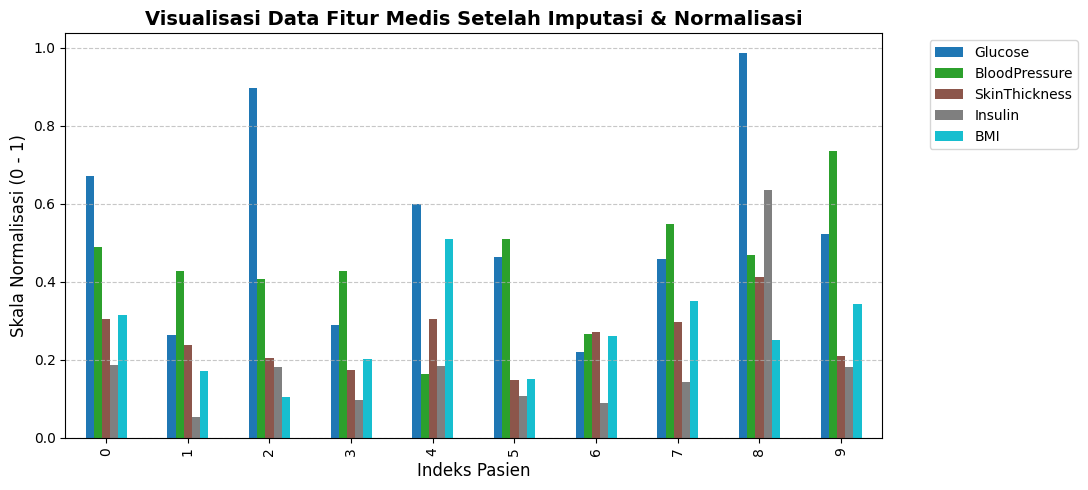


STUDI KASUS 2: KLASTERING CUSTOMER SEGMENTATION (DS_2)

--- 1. Tampilan Data Pelanggan/Individu ---
      Nama  Usia     Gaji Jenis Kelamin
0      Ana    47  4700000     Perempuan
1     Budi    58  5500000     Laki-laki
2  Cecilia    49  5000000     Laki-laki
3     Dino    36  3500000     Laki-laki
4    Erlin     0  3000000     Perempuan
5    Fahmi    38  3500000     Laki-laki
6     Gina    48  4500000     Perempuan
7  Handoko    46        0     Laki-laki
8     Inas    41  4000000     Perempuan

--- 2. Jumlah Missing Value Per Kolom ---
Nama             0
Usia             1
Gaji             1
Jenis Kelamin    0
dtype: int64

--- 3. Data Pelanggan Setelah Imputasi Median ---
      Nama  Usia       Gaji Jenis Kelamin
0      Ana  47.0  4700000.0     Perempuan
1     Budi  58.0  5500000.0     Laki-laki
2  Cecilia  49.0  5000000.0     Laki-laki
3     Dino  36.0  3500000.0     Laki-laki
4    Erlin  46.5  3000000.0     Perempuan
5    Fahmi  38.0  3500000.0     Laki-laki
6     Gina  48.0  4500

/tmp/ipykernel_1176/222180774.py:84: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_customer_clean['Usia'].fillna(df_customer_clean['Usia'].median(), inplace=True)
/tmp/ipykernel_1176/222180774.py:85: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].

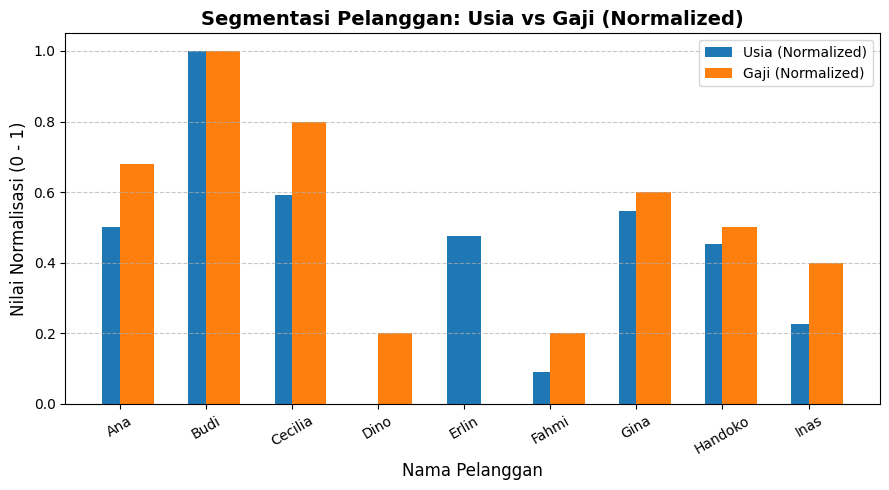

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler

print("=========================================================")
print("STUDI KASUS 1: KLASIFIKASI DIAGNOSIS MEDIS (DIABETES)")
print("=========================================================")

# 1. Load Dataset Diabetes
try:
    df_diabetes = pd.read_csv('diabetes (2).csv')
except FileNotFoundError:
    # Jika file diunggah dengan nama 'diabetes.csv'
    df_diabetes = pd.read_csv('diabetes.csv')

print("\n--- 1. Tampilan 5 Baris Pertama Data Diabetes ---")
print(df_diabetes.head())

# Pada data diabetes, nilai 0 pada kolom klinis merupakan missing value implisit
medical_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("\n--- 2. Identifikasi Missing Value (Nilai 0) ---")
for col in medical_cols:
    zero_count = (df_diabetes[col] == 0).sum()
    print(f"Jumlah nilai 0 pada kolom {col}: {zero_count}")

# Mengubah nilai 0 menjadi NaN agar dikenali sebagai Missing Value
df_diabetes_clean = df_diabetes.copy()
df_diabetes_clean[medical_cols] = df_diabetes_clean[medical_cols].replace(0, np.nan)

# 3. Penanganan Missing Value menggunakan KNN Imputer (Advanced Imputation)
imputer = KNNImputer(n_neighbors=5)
df_diabetes_imputed = pd.DataFrame(
    imputer.fit_transform(df_diabetes_clean),
    columns=df_diabetes.columns
)

print("\n--- 3. Jumlah Missing Value Setelah Ditangani (KNN Imputer) ---")
print(df_diabetes_imputed[medical_cols].isnull().sum())

# 4. Normalisasi Data (Min-Max Scaling)
scaler = MinMaxScaler()
df_diabetes_norm = pd.DataFrame(
    scaler.fit_transform(df_diabetes_imputed),
    columns=df_diabetes.columns
)

print("\n--- 4. Hasil Data Diabetes Setelah Normalisasi (Min-Max) ---")
print(df_diabetes_norm[medical_cols].head())

# Visualisasi
plt.figure(figsize=(10, 5))
df_diabetes_norm[medical_cols].head(10).plot(kind='bar', figsize=(11, 5), colormap='tab10')
plt.title('Visualisasi Data Fitur Medis Setelah Imputasi & Normalisasi', fontsize=14, fontweight='bold')
plt.xlabel('Indeks Pasien', fontsize=12)
plt.ylabel('Skala Normalisasi (0 - 1)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


print("\n=========================================================")
print("STUDI KASUS 2: KLASTERING CUSTOMER SEGMENTATION (DS_2)")
print("=========================================================")

# 1. Load Dataset DS_2
df_customer = pd.read_csv('DS_2.csv', sep=';')

print("\n--- 1. Tampilan Data Pelanggan/Individu ---")
print(df_customer)

# Identifikasi nilai 0 sebagai missing value pada Usia dan Gaji
df_customer_clean = df_customer.copy()
df_customer_clean['Usia'] = df_customer_clean['Usia'].replace(0, np.nan)
df_customer_clean['Gaji'] = df_customer_clean['Gaji'].replace(0, np.nan)

print("\n--- 2. Jumlah Missing Value Per Kolom ---")
print(df_customer_clean.isnull().sum())

# 3. Penanganan Missing Value menggunakan Median
df_customer_clean['Usia'].fillna(df_customer_clean['Usia'].median(), inplace=True)
df_customer_clean['Gaji'].fillna(df_customer_clean['Gaji'].median(), inplace=True)

print("\n--- 3. Data Pelanggan Setelah Imputasi Median ---")
print(df_customer_clean)

# 4. Normalisasi Data
scaler_cust = MinMaxScaler()
cust_numeric = ['Usia', 'Gaji']
df_customer_norm = df_customer_clean.copy()
df_customer_norm[cust_numeric] = scaler_cust.fit_transform(df_customer_clean[cust_numeric])

print("\n--- 4. Hasil Normalisasi Skala 0 - 1 ---")
print(df_customer_norm[['Nama', 'Usia', 'Gaji']])

# Visualisasi Bar Chart
plt.figure(figsize=(9, 5))
plt.bar(df_customer_norm['Nama'], df_customer_norm['Usia'], width=0.4, label='Usia (Normalized)', align='center')
plt.bar(df_customer_norm['Nama'], df_customer_norm['Gaji'], width=0.4, label='Gaji (Normalized)', align='edge')
plt.title('Segmentasi Pelanggan: Usia vs Gaji (Normalized)', fontsize=14, fontweight='bold')
plt.xlabel('Nama Pelanggan', fontsize=12)
plt.ylabel('Nilai Normalisasi (0 - 1)', fontsize=12)
plt.xticks(rotation=30)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()